# Ski Sensor Dataset Cleaning Notebook

## Standarizes column naming and format for the phone GPS + left & right boot sensor streams.

### File structure
```
├── TimeStamps_FieldMeasurements.xlsx      // Field Measurements - Edge Condition
└── Ski Daten - Rohdaten                   // Raw IMU Sensor data - High resolution
    ├── DATE Run X.csv 
    └── DATE_rundetails                    // Analytics from sensor data per adquisition
        └── DATE_runDetails.json


```
Set `input_file`, which contains metadata rows followed by semicolon-delimited sensor data with comma decimal separators. 
    
- Extract non-tabular metadata rows into `metadata.txt`
- Repairs trailing comma artifacts
- Creates unique, descriptive column names for phone, left boot, and right boot fields
- Parses timestamps and numeric values
- Removes empty/duplicate rows
- Exports a cleaned CSV and a cleaning report

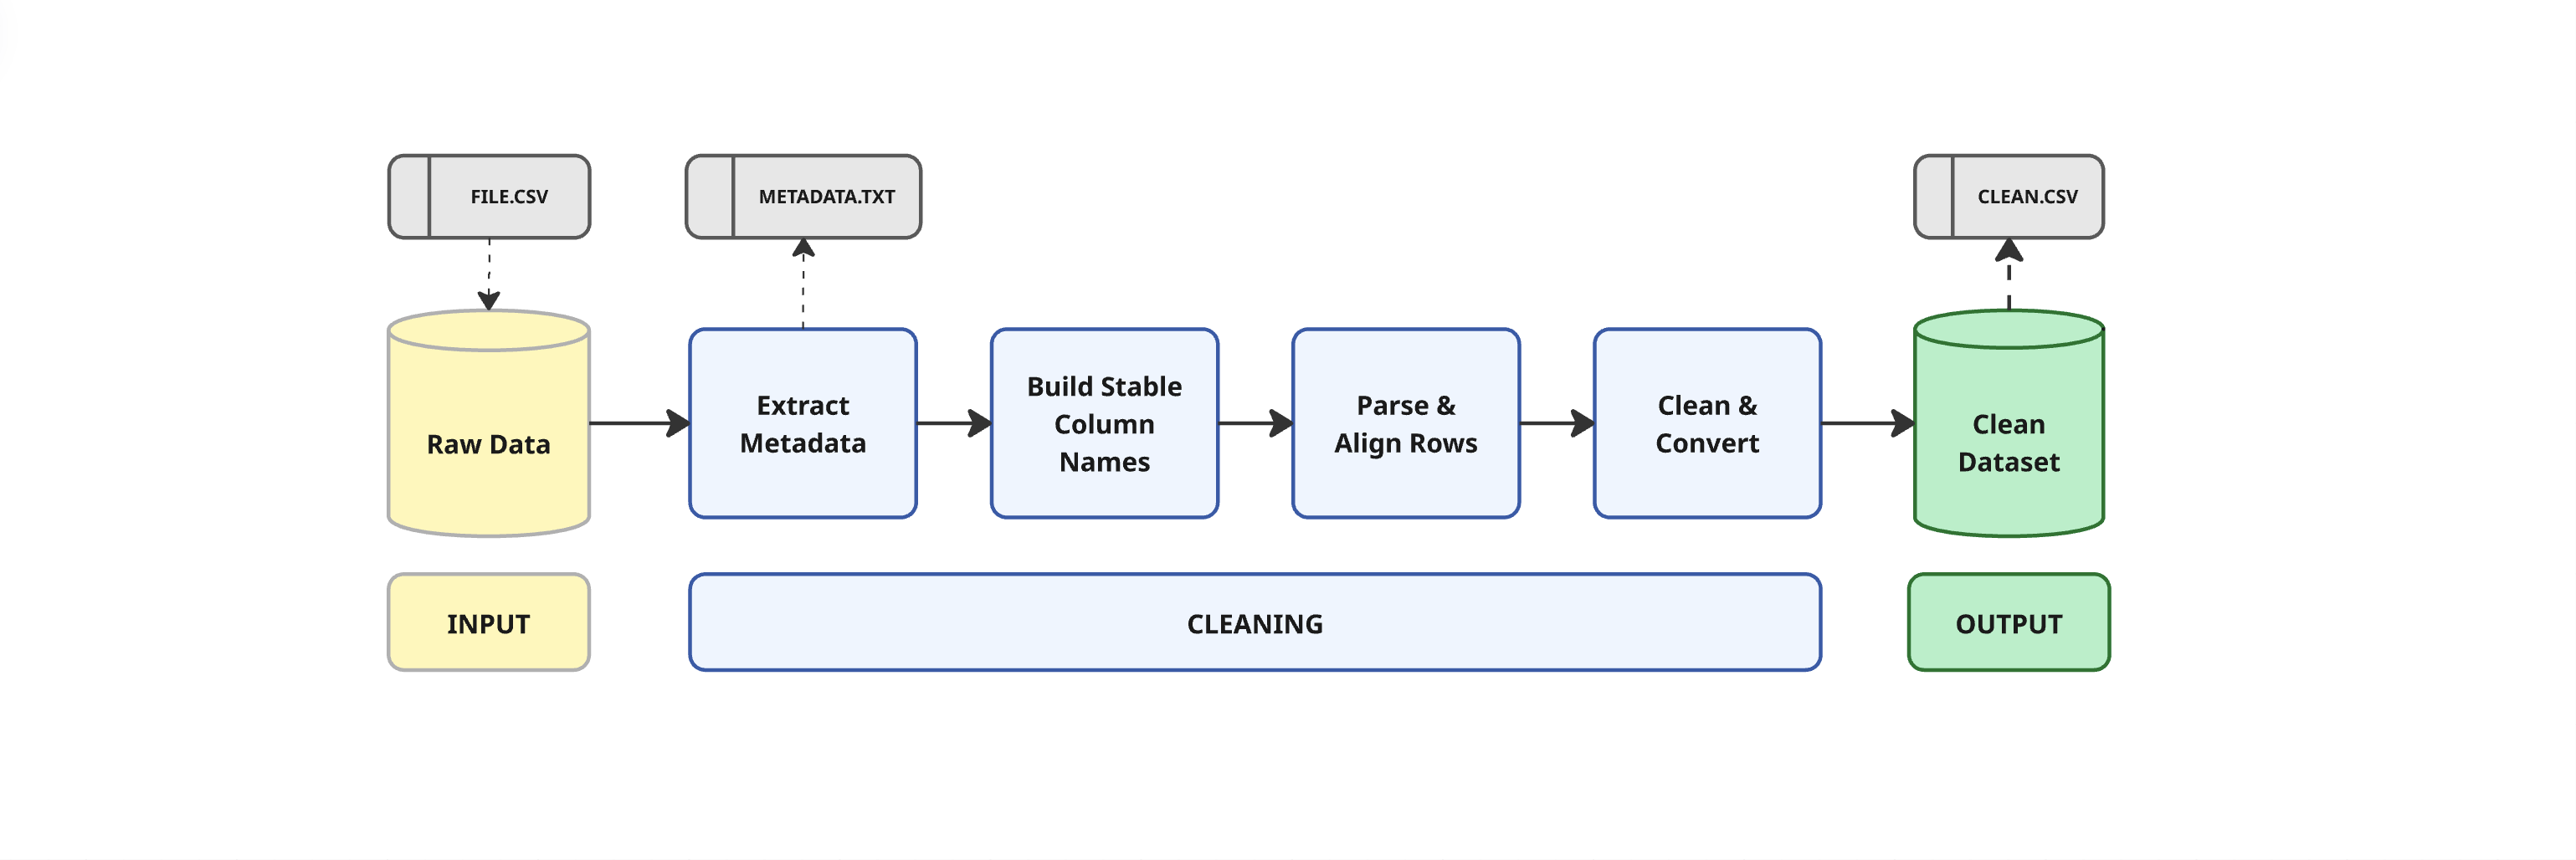

In [1]:
import re
import pandas as pd
import geopandas as gpd
from pathlib import Path
import matplotlib.pyplot as plt

# Data Exploration

## 1. Split metadata and sensor table into separate files

The file contains:
- Metadata rows
- The real sensor data

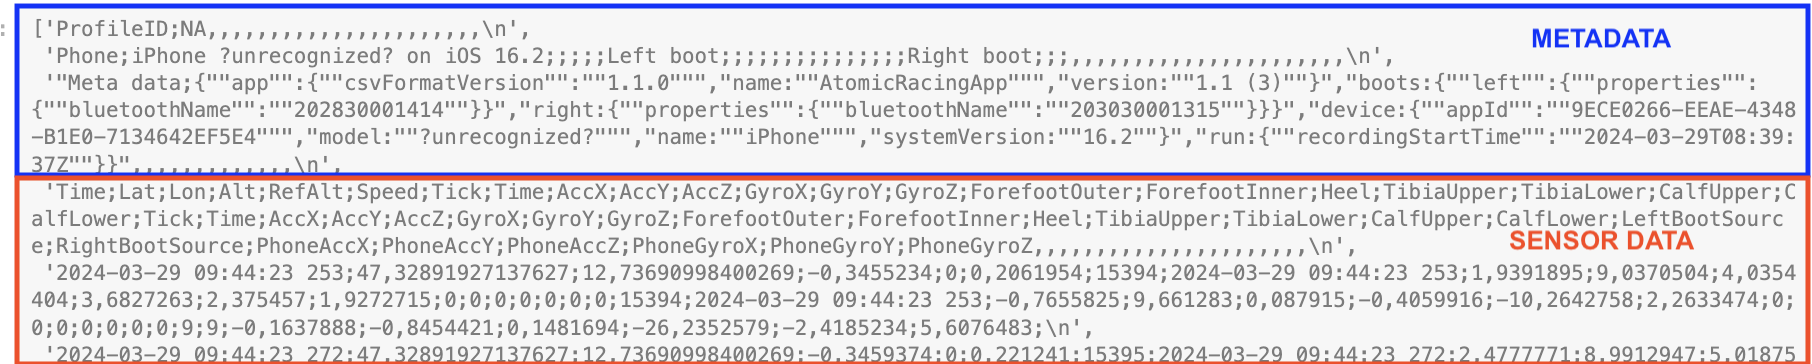

In [2]:
# Load raw file

input_file = r"C:\Users\nsalazar\Research Studios Austria Forschungsgesellschaft mbH\ISPACE - Internship_Nicole\data\Ski Daten - Rohdaten\2024-03-29_09-44-23 Run 1.csv"

with open(input_file, "r", encoding="utf-8", errors="replace") as f:
    lines = f.readlines()

# Find where the actual table starts
table_start_idx = None

for i, line in enumerate(lines):
    if line.startswith("Time;"):
        table_start_idx = i
        break

# Split content
metadata_lines = lines[:table_start_idx]
table_lines = lines[table_start_idx:]

# Save metadata separately
with open("metadata.txt", "w", encoding="utf-8") as f:
    f.writelines(metadata_lines)

In [3]:
metadata_lines

['ProfileID;NA\n',
 'Phone;iPhone ?unrecognized? on iOS 16.2;;;;;Left boot;;;;;;;;;;;;;;;Right boot;;;\n',
 'Meta data;{"app":{"csvFormatVersion":"1.1.0","name":"AtomicRacingApp","version":"1.1 (3)"},"boots":{"left":{"properties":{"bluetoothName":"202830001414"}},"right":{"properties":{"bluetoothName":"203030001315"}}},"device":{"appId":"9ECE0266-EEAE-4348-B1E0-7134642EF5E4","model":"?unrecognized?","name":"iPhone","systemVersion":"16.2"},"run":{"recordingStartTime":"2024-03-29T08:39:37Z"}}\n']

In [4]:
table_lines

['Time;Lat;Lon;Alt;RefAlt;Speed;Tick;Time;AccX;AccY;AccZ;GyroX;GyroY;GyroZ;ForefootOuter;ForefootInner;Heel;TibiaUpper;TibiaLower;CalfUpper;CalfLower;Tick;Time;AccX;AccY;AccZ;GyroX;GyroY;GyroZ;ForefootOuter;ForefootInner;Heel;TibiaUpper;TibiaLower;CalfUpper;CalfLower;LeftBootSource;RightBootSource;PhoneAccX;PhoneAccY;PhoneAccZ;PhoneGyroX;PhoneGyroY;PhoneGyroZ\n',
 '2024-03-29 09:44:23 253;47,32891927137627;12,73690998400269;-0,3455234;0;0,2061954;15394;2024-03-29 09:44:23 253;1,9391895;9,0370504;4,0354404;3,6827263;2,375457;1,9272715;0;0;0;0;0;0;0;15394;2024-03-29 09:44:23 253;-0,7655825;9,661283;0,087915;-0,4059916;-10,2642758;2,2633474;0;0;0;0;0;0;0;9;9;-0,1637888;-0,8454421;0,1481694;-26,2352579;-2,4185234;5,6076483;\n',
 '2024-03-29 09:44:23 272;47,32891927137627;12,73690998400269;-0,3459374;0;0,221241;15395;2024-03-29 09:44:23 272;2,4777771;8,9912947;5,0187503;3,2937446;3,227298;1,5031914;0;0;0;0;0;0;0;15395;2024-03-29 09:44:23 272;-1,3172498;9,485411;0,8316967;0,0033651;-7,475978

### 1.2 Extract the real sensor table



In [5]:
# Remove padding commas that appear at the end of some lines

def strip_trailing_comma_artifacts(value: str) -> str:
    return re.sub(r",+$", "", value.strip())
    

In [6]:
# Read raw file again

with open(input_file, "r", encoding="utf-8", errors="replace") as f:
    lines = f.readlines()

# Find header line
header_idx = None

for idx, line in enumerate(lines):
    if line.startswith("Time;Lat;Lon"):
        header_idx = idx
        break

print("Header row:", table_start_idx)

header_line = lines[header_idx].strip()

# Parse raw header
raw_header = [strip_trailing_comma_artifacts(x) for x in header_line.split(";")]
raw_header = [h for h in raw_header if h != ""]

print("Detected sensor header fields:", len(raw_header))


Header row: 3
Detected sensor header fields: 44


## 2. Stable schema definition


In [7]:
# Stable schema definition

phone_gps_cols = [
    "phone_time",
    "lat",
    "lon",
    "alt",
    "ref_alt",
    "speed"
]

boot_sensor_cols = [
    "tick",
    "time",
    "acc_x",
    "acc_y",
    "acc_z",
    "gyro_x",
    "gyro_y",
    "gyro_z",
    "forefoot_outer",
    "forefoot_inner",
    "heel",
    "tibia_upper",
    "tibia_lower",
    "calf_upper",
    "calf_lower"
]

source_and_phone_cols = [
    "left_boot_source",
    "right_boot_source",
    "phone_acc_x",
    "phone_acc_y",
    "phone_acc_z",
    "phone_gyro_x",
    "phone_gyro_y",
    "phone_gyro_z"
]

columns = (
    phone_gps_cols
    + [f"left_{c}" for c in boot_sensor_cols]
    + [f"right_{c}" for c in boot_sensor_cols]
    + source_and_phone_cols
)

print("Stable columns assigned:", len(columns))
columns


Stable columns assigned: 44


['phone_time',
 'lat',
 'lon',
 'alt',
 'ref_alt',
 'speed',
 'left_tick',
 'left_time',
 'left_acc_x',
 'left_acc_y',
 'left_acc_z',
 'left_gyro_x',
 'left_gyro_y',
 'left_gyro_z',
 'left_forefoot_outer',
 'left_forefoot_inner',
 'left_heel',
 'left_tibia_upper',
 'left_tibia_lower',
 'left_calf_upper',
 'left_calf_lower',
 'right_tick',
 'right_time',
 'right_acc_x',
 'right_acc_y',
 'right_acc_z',
 'right_gyro_x',
 'right_gyro_y',
 'right_gyro_z',
 'right_forefoot_outer',
 'right_forefoot_inner',
 'right_heel',
 'right_tibia_upper',
 'right_tibia_lower',
 'right_calf_upper',
 'right_calf_lower',
 'left_boot_source',
 'right_boot_source',
 'phone_acc_x',
 'phone_acc_y',
 'phone_acc_z',
 'phone_gyro_x',
 'phone_gyro_y',
 'phone_gyro_z']

## 3. Parse data rows

In [8]:
table_lines = lines[header_idx + 1:]

rows = [
    [strip_trailing_comma_artifacts(v) for v in line.rstrip("\n").split(";")]
    for line in table_lines
]

# Remove fully empty rows
rows = [r for r in rows if any(v != "" for v in r)]

max_len = max(len(r) for r in rows)

print("Maximum row length:", max_len)
print("Schema length:", len(columns))

Maximum row length: 45
Schema length: 44


In [9]:
folder_path = r'C:\Users\nsalazar\Research Studios Austria Forschungsgesellschaft mbH\ISPACE - Internship_Nicole\data\Ski Daten - Rohdaten'

def folder_file_report(folder_path):
    """
    Returns a report of the total rows and columns for each CSV/Excel file
    in the specified folder.

    Parameters
    ----------
    folder_path : str
        Path to the folder containing the files.

    Returns
    -------
    pandas.DataFrame
        Report containing:
        - File Name
        - File Type
        - Rows
        - Columns
    """
    report = []

    folder = Path(folder_path)

    for file in folder.iterdir():
        if file.is_file():
            try:
                if file.suffix.lower() == ".csv":
                    df = pd.read_csv(file)
                elif file.suffix.lower() in [".xlsx", ".xls"]:
                    df = pd.read_excel(file)
                else:
                    continue

                report.append({
                    "File Name": file.name,
                    "File Type": file.suffix,
                    "Rows": df.shape[0],
                    "Columns": df.shape[1]
                })

            except Exception as e:
                report.append({
                    "File Name": file.name,
                    "File Type": file.suffix,
                    "Rows": None,
                    "Columns": None,
                    "Error": str(e)
                })

    return pd.DataFrame(report)

folder_file_report(folder_path)

,File Name,File Type,Rows,Columns,Error
0,2024-03-29_09-44-23 Run 1.csv,.csv,None,None,Error tokenizing data. C error: Expected 1 fie...
1,2024-03-29_10-29-07 Run 1.csv,.csv,None,None,Error tokenizing data. C error: Expected 1 fie...
2,2024-03-29_10-33-47 Run 1.csv,.csv,None,None,Error tokenizing data. C error: Expected 1 fie...
3,2024-03-29_10-45-40 Run 1.csv,.csv,None,None,Error tokenizing data. C error: Expected 1 fie...
4,2024-03-29_10-50-19 Run 1.csv,.csv,None,None,Error tokenizing data. C error: Expected 1 fie...
5,2024-03-29_11-05-44 Run 1.csv,.csv,None,None,Error tokenizing data. C error: Expected 1 fie...
6,2024-03-29_11-10-01 Run 1.csv,.csv,None,None,Error tokenizing data. C error: Expected 1 fie...
7,2024-03-29_11-26-05 Run 1.csv,.csv,None,None,Error tokenizing data. C error: Expected 1 fie...
8,2024-03-29_11-32-27 Run 1.csv,.csv,None,None,Error tokenizing data. C error: Expected 1 fie...
9,2024-03-29_11-47-11 Run 1.csv,.csv,None,None,Error tokenizing data. C error: Expected 1 fie...


In [10]:
# Expand schema if needed
# if max_len > len(columns):
#    extra = max_len - len(columns)
#   columns.extend([f"extra_col_{i}" for i in range(extra)])

In [11]:
normalized_rows = [] 
for r in rows:

    if len(r) < len(columns):
        r.extend([None] * (len(columns) - len(r)))

    elif len(r) > len(columns):
        r = r[:len(columns)]

    normalized_rows.append(r)



df = pd.DataFrame(normalized_rows, columns=columns)

df = df.replace(",",".", regex=True)

print(df.shape)
df.head()

(9719, 44)


,phone_time,lat,lon,alt,ref_alt,speed,left_tick,left_time,left_acc_x,left_acc_y,...,right_calf_upper,right_calf_lower,left_boot_source,right_boot_source,phone_acc_x,phone_acc_y,phone_acc_z,phone_gyro_x,phone_gyro_y,phone_gyro_z
0,2024-03-29 09:44:23 253,47.32891927137627,12.73690998400269,-0.3455234,0,0.2061954,15394,2024-03-29 09:44:23 253,1.9391895,9.0370504,...,0,0,9,9,-0.1637888,-0.8454421,0.1481694,-26.2352579,-2.4185234,5.6076483
1,2024-03-29 09:44:23 272,47.32891927137627,12.73690998400269,-0.3459374,0,0.221241,15395,2024-03-29 09:44:23 272,2.4777771,8.9912947,...,0,0,9,9,-0.1359291,-0.8324607,0.1084843,-20.1110082,-3.0002905,4.267318
2,2024-03-29 09:44:23 290,47.32891927137627,12.73690998400269,-0.3474794,0,0.2362866,15396,2024-03-29 09:44:23 290,2.8041353,8.8785635,...,0,0,9,9,-0.1261975,-0.8148757,0.0702778,-13.1766533,-5.5027969,2.7095209
3,2024-03-29 09:44:23 309,47.32891927137627,12.73690998400269,-0.3508131,0,0.2513322,15397,2024-03-29 09:44:23 309,2.9619016,8.7386092,...,0,0,9,9,-0.1289095,-0.8120753,0.0250193,-4.6557472,-12.3713915,0.0193956
4,2024-03-29 09:44:23 327,47.32891927137627,12.73690998400269,-0.3541468,0,0.2663778,15398,2024-03-29 09:44:23 327,2.696023,8.589344,...,0,0,9,9,-0.1457315,-0.8194708,0.0166202,3.8190404,-21.1965177,-4.0844024


In [12]:
# Convert timestamps like (remove spaces between seconds nd miliseconds):
# 2024-03-29 09:44:23 309
# ->
# 2024-03-29 09:44:23.309

time_cols = ["phone_time", "left_time", "right_time"]

for col in time_cols:
    df[col] = (
        df[col]
        .astype(str)
        .str.replace(
            r"(\d{2}:\d{2}:\d{2}) (\d{3})$",
            r"\1.\2",
            regex=True
        )
    )

# Check result
df[time_cols].head()

,phone_time,left_time,right_time
0,2024-03-29 09:44:23.253,2024-03-29 09:44:23.253,2024-03-29 09:44:23.253
1,2024-03-29 09:44:23.272,2024-03-29 09:44:23.272,2024-03-29 09:44:23.272
2,2024-03-29 09:44:23.290,2024-03-29 09:44:23.290,2024-03-29 09:44:23.290
3,2024-03-29 09:44:23.309,2024-03-29 09:44:23.309,2024-03-29 09:44:23.309
4,2024-03-29 09:44:23.327,2024-03-29 09:44:23.327,2024-03-29 09:44:23.327


In [13]:
df.describe()

,phone_time,lat,lon,alt,ref_alt,speed,left_tick,left_time,left_acc_x,left_acc_y,...,right_calf_upper,right_calf_lower,left_boot_source,right_boot_source,phone_acc_x,phone_acc_y,phone_acc_z,phone_gyro_x,phone_gyro_y,phone_gyro_z
count,9719,9719,9719,9719,9719,9719,9719,9719,9719,9719,...,9719,9719,9719,9719,9719,9719,9719,9719,9719,9719
unique,9719,155,155,8426,1,5604,9719,9719,9701,9550,...,1,1,1,2,9715,9718,9716,9719,9718,9719
top,2024-03-29 09:47:23.217,47.32597008932284,12.72821832668964,-204.8986816,0,0,25112,2024-03-29 09:47:23.217,0.6077987,9.5429175,...,0,0,9,9,-0.507654,-0.9625743,0.0326962,10.4675233,1.7093796,7.0070038
freq,1,486,486,115,9719,4116,1,1,12,17,...,9719,9719,9719,9689,2,2,2,1,2,1


In [14]:
df.isnull().sum()

phone_time              0
lat                     0
lon                     0
alt                     0
ref_alt                 0
speed                   0
left_tick               0
left_time               0
left_acc_x              0
left_acc_y              0
left_acc_z              0
left_gyro_x             0
left_gyro_y             0
left_gyro_z             0
left_forefoot_outer     0
left_forefoot_inner     0
left_heel               0
left_tibia_upper        0
left_tibia_lower        0
left_calf_upper         0
left_calf_lower         0
right_tick              0
right_time              0
right_acc_x             0
right_acc_y             0
right_acc_z             0
right_gyro_x            0
right_gyro_y            0
right_gyro_z            0
right_forefoot_outer    0
right_forefoot_inner    0
right_heel              0
right_tibia_upper       0
right_tibia_lower       0
right_calf_upper        0
right_calf_lower        0
left_boot_source        0
right_boot_source       0
phone_acc_x 

In [15]:
#unique values (coordinates)
a= pd.unique(df.lat)
a= pd.Series(a).value_counts()
a

47.32891927137627    1
47.32891558548263    1
47.32890557446658    1
47.32888848737288    1
47.32886648901201    1
                    ..
47.32596116757693    1
47.325960971425      1
47.32596168520086    1
47.32596097498238    1
47.32596043060109    1
Name: count, Length: 155, dtype: int64

In [16]:
# Current Datatype
df.dtypes

phone_time              object
lat                     object
lon                     object
alt                     object
ref_alt                 object
speed                   object
left_tick               object
left_time               object
left_acc_x              object
left_acc_y              object
left_acc_z              object
left_gyro_x             object
left_gyro_y             object
left_gyro_z             object
left_forefoot_outer     object
left_forefoot_inner     object
left_heel               object
left_tibia_upper        object
left_tibia_lower        object
left_calf_upper         object
left_calf_lower         object
right_tick              object
right_time              object
right_acc_x             object
right_acc_y             object
right_acc_z             object
right_gyro_x            object
right_gyro_y            object
right_gyro_z            object
right_forefoot_outer    object
right_forefoot_inner    object
right_heel              object
right_ti

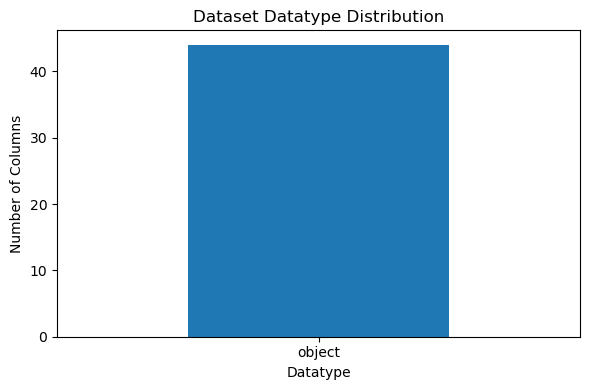

In [17]:
# Visual representation of datatype distribution
# Count datatypes

dtype_counts = df.dtypes.astype(str).value_counts()

# Plot
plt.figure(figsize=(6, 4))
dtype_counts.plot(kind="bar")

plt.title("Dataset Datatype Distribution")
plt.xlabel("Datatype")
plt.ylabel("Number of Columns")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Convert datatypes

In [18]:
# Convert datatypes

datetime_cols = [
    "phone_time",
    "left_time",
    "right_time"
]

for col in datetime_cols:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

for col in df.columns:
    if col not in datetime_cols:
        df[col] = pd.to_numeric(df[col], errors="raise")

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9719 entries, 0 to 9718
Data columns (total 44 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   phone_time            9719 non-null   datetime64[ns]
 1   lat                   9719 non-null   float64       
 2   lon                   9719 non-null   float64       
 3   alt                   9719 non-null   float64       
 4   ref_alt               9719 non-null   int64         
 5   speed                 9719 non-null   float64       
 6   left_tick             9719 non-null   int64         
 7   left_time             9719 non-null   datetime64[ns]
 8   left_acc_x            9719 non-null   float64       
 9   left_acc_y            9719 non-null   float64       
 10  left_acc_z            9719 non-null   float64       
 11  left_gyro_x           9719 non-null   float64       
 12  left_gyro_y           9719 non-null   float64       
 13  left_gyro_z       

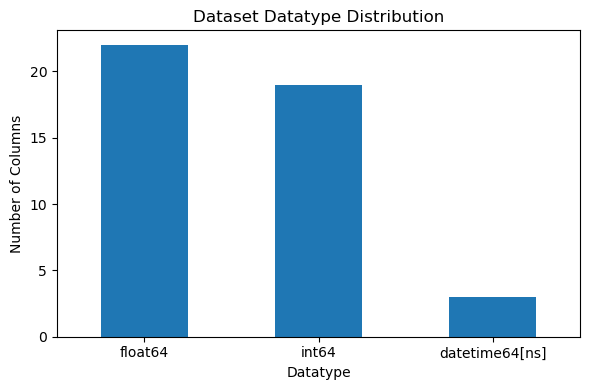

In [19]:
# Visual representation of datatype distribution

import matplotlib.pyplot as plt

# Count datatypes
dtype_counts = df.dtypes.astype(str).value_counts()

# Plot
plt.figure(figsize=(6, 4))
dtype_counts.plot(kind="bar")

plt.title("Dataset Datatype Distribution")
plt.xlabel("Datatype")
plt.ylabel("Number of Columns")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4.1 Add `run` and `edge_condition` columns

Same enrichment used in the batch workflow (see section 2.1 below): the run number comes from `input_file`'s name, and `edge_condition` is looked up from `TimeStamps_FieldMeasurements.xlsx` using the run's start date/time.

In [20]:
# Path to the field measurements / edge condition log
field_measurements_file = "TimeStamps_FieldMeasurements.xlsx"

fm_df = pd.read_excel(field_measurements_file)
fm_df["Date"] = fm_df["Date"].ffill()
fm_df["datetime"] = pd.to_datetime(
    fm_df["Date"].dt.strftime("%Y-%m-%d") + " " + fm_df["Time"].astype(str),
    errors="coerce"
)
fm_df = fm_df.dropna(subset=["datetime"]).sort_values("datetime").reset_index(drop=True)

# Parse the run number and recording start time from the file name, e.g.
# "2024-03-29_09-44-23_Run_1_sample.csv" -> run=1, start=2024-03-29 09:44:23
run_match = re.search(
    r"(?P<date>\d{4}-\d{2}-\d{2})[_ ](?P<time>\d{2}-\d{2}-\d{2})[_ ]Run[_ ]?(?P<run>\d+)",
    Path(input_file).name,
    re.IGNORECASE
)

run_number = int(run_match.group("run")) if run_match else None
run_start = (
    pd.to_datetime(f"{run_match.group('date')} {run_match.group('time').replace('-', ':')}")
    if run_match else None
)

edge_condition = None
if run_start is not None:
    same_day_before_start = fm_df[
        (fm_df["datetime"].dt.date == run_start.date())
        & (fm_df["datetime"] <= run_start)
    ]
    if not same_day_before_start.empty:
        edge_condition = same_day_before_start.iloc[-1]["Edge Condition"]

df["run"] = run_number
df["edge_condition"] = edge_condition

print("run:", run_number, "| edge_condition:", edge_condition)
df[["run", "edge_condition"]].head()


run: 1 | edge_condition: None


,run,edge_condition
0,1,None
1,1,None
2,1,None
3,1,None
4,1,None


In [21]:
df

,phone_time,lat,lon,alt,ref_alt,speed,left_tick,left_time,left_acc_x,left_acc_y,...,left_boot_source,right_boot_source,phone_acc_x,phone_acc_y,phone_acc_z,phone_gyro_x,phone_gyro_y,phone_gyro_z,run,edge_condition
0,2024-03-29 09:44:23.253,47.328919,12.736910,-0.345523,0,0.206195,15394,2024-03-29 09:44:23.253,1.939189,9.037050,...,9,9,-0.163789,-0.845442,0.148169,-26.235258,-2.418523,5.607648,1,None
1,2024-03-29 09:44:23.272,47.328919,12.736910,-0.345937,0,0.221241,15395,2024-03-29 09:44:23.272,2.477777,8.991295,...,9,9,-0.135929,-0.832461,0.108484,-20.111008,-3.000291,4.267318,1,None
2,2024-03-29 09:44:23.290,47.328919,12.736910,-0.347479,0,0.236287,15396,2024-03-29 09:44:23.290,2.804135,8.878564,...,9,9,-0.126197,-0.814876,0.070278,-13.176653,-5.502797,2.709521,1,None
3,2024-03-29 09:44:23.309,47.328919,12.736910,-0.350813,0,0.251332,15397,2024-03-29 09:44:23.309,2.961902,8.738609,...,9,9,-0.128910,-0.812075,0.025019,-4.655747,-12.371391,0.019396,1,None
4,2024-03-29 09:44:23.327,47.328919,12.736910,-0.354147,0,0.266378,15398,2024-03-29 09:44:23.327,2.696023,8.589344,...,9,9,-0.145732,-0.819471,0.016620,3.819040,-21.196518,-4.084402,1,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9714,2024-03-29 09:47:23.143,47.325960,12.728198,-205.427124,0,0.000000,25108,2024-03-29 09:47:23.143,0.607799,9.542917,...,9,11,-0.130869,-0.301292,-0.977500,22.957511,-24.987224,-14.177826,1,None
9715,2024-03-29 09:47:23.161,47.325960,12.728198,-205.427124,0,0.000000,25109,2024-03-29 09:47:23.161,0.607799,9.542917,...,9,11,-0.103489,-0.294336,-0.938088,22.414449,-36.645144,-17.067272,1,None
9716,2024-03-29 09:47:23.180,47.325960,12.728198,-205.427124,0,0.000000,25110,2024-03-29 09:47:23.180,0.607799,9.542917,...,9,11,-0.081894,-0.317408,-0.848283,25.624349,-40.362033,-11.116989,1,None
9717,2024-03-29 09:47:23.198,47.325960,12.728198,-205.427124,0,0.000000,25111,2024-03-29 09:47:23.198,0.607799,9.542917,...,9,11,-0.142621,-0.396968,-0.701878,33.851811,-34.515358,3.975709,1,None


## 5. Save cleaned dataset (Only one: input_file)


In [22]:
output_file = "test_delete_cleaned.csv"

df.to_csv(output_file, index=False)

print("Saved cleaned dataset:")
print(output_file)


Saved cleaned dataset:
test_delete_cleaned.csv


## 6. CSV to GeoJSON

In [23]:
# Read CSV
df = pd.read_csv(output_file)

# Create geometry from lon/lat
gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["lon"], df["lat"]),
    crs="EPSG:4326"
)

# Transform to Pseudo-Mercator
gdf_3857 = gdf.to_crs("EPSG:3857")

# Save result
gdf_3857.to_file("output_3857.geojson", driver="GeoJSON")

# Export to GeoJSON
gdf.to_file(r"outpudelete.geojson", driver="GeoJSON")

In [24]:
gdf

,phone_time,lat,lon,alt,ref_alt,speed,left_tick,left_time,left_acc_x,left_acc_y,...,right_boot_source,phone_acc_x,phone_acc_y,phone_acc_z,phone_gyro_x,phone_gyro_y,phone_gyro_z,run,edge_condition,geometry
0,2024-03-29 09:44:23.253,47.328919,12.736910,-0.345523,0,0.206195,15394,2024-03-29 09:44:23.253,1.939189,9.037050,...,9,-0.163789,-0.845442,0.148169,-26.235258,-2.418523,5.607648,1,NaN,POINT (12.73691 47.32892)
1,2024-03-29 09:44:23.272,47.328919,12.736910,-0.345937,0,0.221241,15395,2024-03-29 09:44:23.272,2.477777,8.991295,...,9,-0.135929,-0.832461,0.108484,-20.111008,-3.000291,4.267318,1,NaN,POINT (12.73691 47.32892)
2,2024-03-29 09:44:23.290,47.328919,12.736910,-0.347479,0,0.236287,15396,2024-03-29 09:44:23.290,2.804135,8.878564,...,9,-0.126197,-0.814876,0.070278,-13.176653,-5.502797,2.709521,1,NaN,POINT (12.73691 47.32892)
3,2024-03-29 09:44:23.309,47.328919,12.736910,-0.350813,0,0.251332,15397,2024-03-29 09:44:23.309,2.961902,8.738609,...,9,-0.128910,-0.812075,0.025019,-4.655747,-12.371391,0.019396,1,NaN,POINT (12.73691 47.32892)
4,2024-03-29 09:44:23.327,47.328919,12.736910,-0.354147,0,0.266378,15398,2024-03-29 09:44:23.327,2.696023,8.589344,...,9,-0.145732,-0.819471,0.016620,3.819040,-21.196518,-4.084402,1,NaN,POINT (12.73691 47.32892)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9714,2024-03-29 09:47:23.143,47.325960,12.728198,-205.427124,0,0.000000,25108,2024-03-29 09:47:23.143,0.607799,9.542917,...,11,-0.130869,-0.301292,-0.977500,22.957511,-24.987224,-14.177826,1,NaN,POINT (12.7282 47.32596)
9715,2024-03-29 09:47:23.161,47.325960,12.728198,-205.427124,0,0.000000,25109,2024-03-29 09:47:23.161,0.607799,9.542917,...,11,-0.103489,-0.294336,-0.938088,22.414449,-36.645144,-17.067272,1,NaN,POINT (12.7282 47.32596)
9716,2024-03-29 09:47:23.180,47.325960,12.728198,-205.427124,0,0.000000,25110,2024-03-29 09:47:23.180,0.607799,9.542917,...,11,-0.081894,-0.317408,-0.848283,25.624349,-40.362033,-11.116989,1,NaN,POINT (12.7282 47.32596)
9717,2024-03-29 09:47:23.198,47.325960,12.728198,-205.427124,0,0.000000,25111,2024-03-29 09:47:23.198,0.607799,9.542917,...,11,-0.142621,-0.396968,-0.701878,33.851811,-34.515358,3.975709,1,NaN,POINT (12.7282 47.32596)


In [25]:
gdf_3857

,phone_time,lat,lon,alt,ref_alt,speed,left_tick,left_time,left_acc_x,left_acc_y,...,right_boot_source,phone_acc_x,phone_acc_y,phone_acc_z,phone_gyro_x,phone_gyro_y,phone_gyro_z,run,edge_condition,geometry
0,2024-03-29 09:44:23.253,47.328919,12.736910,-0.345523,0,0.206195,15394,2024-03-29 09:44:23.253,1.939189,9.037050,...,9,-0.163789,-0.845442,0.148169,-26.235258,-2.418523,5.607648,1,NaN,POINT (1417866.334 5995928.304)
1,2024-03-29 09:44:23.272,47.328919,12.736910,-0.345937,0,0.221241,15395,2024-03-29 09:44:23.272,2.477777,8.991295,...,9,-0.135929,-0.832461,0.108484,-20.111008,-3.000291,4.267318,1,NaN,POINT (1417866.334 5995928.304)
2,2024-03-29 09:44:23.290,47.328919,12.736910,-0.347479,0,0.236287,15396,2024-03-29 09:44:23.290,2.804135,8.878564,...,9,-0.126197,-0.814876,0.070278,-13.176653,-5.502797,2.709521,1,NaN,POINT (1417866.334 5995928.304)
3,2024-03-29 09:44:23.309,47.328919,12.736910,-0.350813,0,0.251332,15397,2024-03-29 09:44:23.309,2.961902,8.738609,...,9,-0.128910,-0.812075,0.025019,-4.655747,-12.371391,0.019396,1,NaN,POINT (1417866.334 5995928.304)
4,2024-03-29 09:44:23.327,47.328919,12.736910,-0.354147,0,0.266378,15398,2024-03-29 09:44:23.327,2.696023,8.589344,...,9,-0.145732,-0.819471,0.016620,3.819040,-21.196518,-4.084402,1,NaN,POINT (1417866.334 5995928.304)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9714,2024-03-29 09:47:23.143,47.325960,12.728198,-205.427124,0,0.000000,25108,2024-03-29 09:47:23.143,0.607799,9.542917,...,11,-0.130869,-0.301292,-0.977500,22.957511,-24.987224,-14.177826,1,NaN,POINT (1416896.563 5995442.36)
9715,2024-03-29 09:47:23.161,47.325960,12.728198,-205.427124,0,0.000000,25109,2024-03-29 09:47:23.161,0.607799,9.542917,...,11,-0.103489,-0.294336,-0.938088,22.414449,-36.645144,-17.067272,1,NaN,POINT (1416896.563 5995442.36)
9716,2024-03-29 09:47:23.180,47.325960,12.728198,-205.427124,0,0.000000,25110,2024-03-29 09:47:23.180,0.607799,9.542917,...,11,-0.081894,-0.317408,-0.848283,25.624349,-40.362033,-11.116989,1,NaN,POINT (1416896.563 5995442.36)
9717,2024-03-29 09:47:23.198,47.325960,12.728198,-205.427124,0,0.000000,25111,2024-03-29 09:47:23.198,0.607799,9.542917,...,11,-0.142621,-0.396968,-0.701878,33.851811,-34.515358,3.975709,1,NaN,POINT (1416896.563 5995442.36)


# Batch Cleaning
## Cleans every raw `.csv` file in a folder

Set `input_folder` to the folder that contains the raw files, then run:

```python
count_files_in_folder(input_folder)
cleaning_results = clean_folder(input_folder)
```

In [26]:
import os
import re
import pandas as pd # type: ignore
from pathlib import Path
import geopandas as gpd
from IPython.display import display, Markdown

# Define input and output folder 
input_folder = r"C:\Users\nsalazar\Research Studios Austria Forschungsgesellschaft mbH\ISPACE - Internship_Nicole\data\Ski Daten - Rohdaten"
output_folder = r"C:\Users\nsalazar\Research Studios Austria Forschungsgesellschaft mbH\ISPACE - Internship_Nicole\data\preprocessing\clean"

## 1. Remove padding commas from the end of a raw field value

In [27]:
def strip_trailing_comma_artifacts(value) -> str:
    if value is None:
        return ""
    return re.sub(r",+$", "", str(value).strip())

# Counts files in a folder
def count_files_in_folder(folder_path, pattern="*.csv", recursive=False):
    folder_path = Path(folder_path).expanduser()

    if not folder_path.exists():
        raise FileNotFoundError(f"Folder does not exist: {folder_path}")

    if not folder_path.is_dir():
        raise NotADirectoryError(f"Path is not a folder: {folder_path}")

    files = folder_path.rglob(pattern) if recursive else folder_path.glob(pattern)
    files = [file for file in files if file.is_file()]

    print(f"Found {len(files)} file(s) matching pattern '{pattern}' in: {folder_path}")
    return len(files)

In [28]:
count_files_in_folder(input_folder)

Found 39 file(s) matching pattern '*.csv' in: C:\Users\nsalazar\Research Studios Austria Forschungsgesellschaft mbH\ISPACE - Internship_Nicole\data\Ski Daten - Rohdaten


39

## 2. Build a fresh copy of the stable schema columns

In [29]:
def build_stable_columns():
    phone_gps_cols = [
        "phone_time",
        "lat",
        "lon",
        "alt",
        "ref_alt",
        "speed"
    ]

    boot_sensor_cols = [
        "tick",
        "time",
        "acc_x",
        "acc_y",
        "acc_z",
        "gyro_x",
        "gyro_y",
        "gyro_z",
        "forefoot_outer",
        "forefoot_inner",
        "heel",
        "tibia_upper",
        "tibia_lower",
        "calf_upper",
        "calf_lower"
    ]

    source_and_phone_cols = [
        "left_boot_source",
        "right_boot_source",
        "phone_acc_x",
        "phone_acc_y",
        "phone_acc_z",
        "phone_gyro_x",
        "phone_gyro_y",
        "phone_gyro_z"
    ]

    return (
        phone_gps_cols
        + [f"left_{col}" for col in boot_sensor_cols]
        + [f"right_{col}" for col in boot_sensor_cols]
        + source_and_phone_cols
    )

## 2.1 Run & Edge Condition enrichment

Adds two new columns to every cleaned run:

- **`run`** — the run number, parsed from the raw file name (e.g. `..._Run_1_...` -> `1`).
- **`edge_condition`** — the ski edge condition (`sharp` / `dull`) that was in effect when the run started, looked up from `TimeStamps_FieldMeasurements.xlsx`.

`TimeStamps_FieldMeasurements.xlsx` contains a `Date`, `Time` and `Edge Condition` column. Each row marks the moment the edge condition changed (dates are only filled on the first row of each day, so they are forward-filled). For a given run, the applicable edge condition is the most recent field measurement timestamp on the *same date* that is at or before the run's start time.

In [30]:
# Path to the field measurements / edge condition log
field_measurements_file = "TimeStamps_FieldMeasurements.xlsx"


In [31]:
def load_field_measurements(field_measurements_file):
    """
    Load the field measurements workbook and return it indexed by a single
    sorted "datetime" column that can be matched against a run's start time.

    The workbook only fills in the "Date" cell on the first row of each day,
    so the Date column is forward-filled before combining it with "Time".
    """
    field_measurements_file = Path(field_measurements_file).expanduser()

    if not field_measurements_file.exists():
        raise FileNotFoundError(f"Field measurements file does not exist: {field_measurements_file}")

    fm_df = pd.read_excel(field_measurements_file)

    fm_df["Date"] = fm_df["Date"].ffill()

    fm_df["datetime"] = pd.to_datetime(
        fm_df["Date"].dt.strftime("%Y-%m-%d") + " " + fm_df["Time"].astype(str),
        errors="coerce"
    )

    fm_df = (
        fm_df
        .dropna(subset=["datetime"])
        .sort_values("datetime")
        .reset_index(drop=True)
    )

    return fm_df


In [32]:
# Matches file names such as:
#   2024-03-29_09-44-23_Run_1_sample.csv
#   2024-03-29_09-44-23 Run 1.csv
RUN_FILENAME_PATTERN = re.compile(
    r"(?P<date>\d{4}-\d{2}-\d{2})[_ ](?P<time>\d{2}-\d{2}-\d{2})[_ ]Run[_ ]?(?P<run>\d+)",
    re.IGNORECASE
)

# Fallback: just grab a run number if the timestamp prefix isn't present
RUN_NUMBER_PATTERN = re.compile(r"Run[_ ]?(?P<run>\d+)", re.IGNORECASE)


def parse_run_info_from_filename(filename):
    """
    Extract the run number and the recording start datetime from a raw file name.

    Returns:
        (run_number, run_start) where run_number is an int (or None) and
        run_start is a pandas.Timestamp (or None) if the date/time prefix
        could not be parsed.
    """
    filename = str(filename)

    match = RUN_FILENAME_PATTERN.search(filename)

    if match:
        run_number = int(match.group("run"))
        run_start = pd.to_datetime(
            f"{match.group('date')} {match.group('time').replace('-', ':')}",
            errors="coerce"
        )
        return run_number, run_start

    # Could not find the timestamp prefix - at least try to recover the run number
    fallback_match = RUN_NUMBER_PATTERN.search(filename)
    run_number = int(fallback_match.group("run")) if fallback_match else None

    return run_number, None


In [33]:
def get_run_and_edge_condition(input_file, field_measurements_df=None):
    """
    Resolve the (run_number, edge_condition) pair for a raw sensor file.

    edge_condition is looked up as the most recent field measurement entry
    that is on the same date and at or before the run's start time. If no
    field measurements table is provided, or no start time / matching entry
    can be found, edge_condition is returned as None.
    """
    input_file = Path(input_file)
    run_number, run_start = parse_run_info_from_filename(input_file.name)

    edge_condition = None

    if field_measurements_df is not None and run_start is not None:
        same_day_before_start = field_measurements_df[
            (field_measurements_df["datetime"].dt.date == run_start.date())
            & (field_measurements_df["datetime"] <= run_start)
        ]

        if not same_day_before_start.empty:
            edge_condition = same_day_before_start.iloc[-1]["Edge Condition"]

    return run_number, edge_condition


## 3. Clean one raw sensor CSV file using the stable schema workflow

In [34]:
def clean_sensor_file(input_file, output_folder=None, metadata_folder=None, save_metadata=True, field_measurements_df=None):
    input_file = Path(input_file).expanduser()

    if not input_file.exists():
        raise FileNotFoundError(f"Input file does not exist: {input_file}")

    if output_folder is None:
        output_folder = input_file.parent / "cleaned"
    else:
        output_folder = Path(output_folder).expanduser()

    if metadata_folder is None:
        metadata_folder = input_file.parent / "metadata"
    else:
        metadata_folder = Path(metadata_folder).expanduser()

    output_folder.mkdir(parents=True, exist_ok=True)

    if save_metadata:
        metadata_folder.mkdir(parents=True, exist_ok=True)

    with open(input_file, "r", encoding="utf-8", errors="replace") as file:
        lines = file.readlines()

    header_idx = None
    for idx, line in enumerate(lines):
        if line.startswith("Time;Lat;Lon"):
            header_idx = idx
            break

    if header_idx is None:
        raise ValueError(f"No sensor table header starting with 'Time;Lat;Lon' found in: {input_file}")

    metadata_lines = lines[:header_idx]
    table_lines = lines[header_idx + 1:]

    if save_metadata:
        metadata_file = metadata_folder / f"{input_file.stem}_metadata.txt"
        with open(metadata_file, "w", encoding="utf-8") as file:
            file.writelines(metadata_lines)
    else:
        metadata_file = None

    rows = [
        [strip_trailing_comma_artifacts(value) for value in line.rstrip("\n").split(";")]
        for line in table_lines
    ]

    rows = [row for row in rows if any(value != "" for value in row)]

    if not rows:
        raise ValueError(f"No data rows found after the header in: {input_file}")

    stable_columns = build_stable_columns()
    max_len = max(len(row) for row in rows)

    if max_len > len(stable_columns):
        extra = max_len - len(stable_columns)
        stable_columns.extend([f"extra_col_{i}" for i in range(extra)])

    normalized_rows = []

    for row in rows:
        if len(row) < len(stable_columns):
            row = row + [None] * (len(stable_columns) - len(row))
        elif len(row) > len(stable_columns):
            row = row[:len(stable_columns)]

        normalized_rows.append(row)

    cleaned_df = pd.DataFrame(normalized_rows, columns=stable_columns)

    # Replace comma decimal separators with dot decimal separators.
    cleaned_df = cleaned_df.replace(",", ".", regex=True)

    datetime_cols = ["phone_time", "left_time", "right_time"]

    for col in datetime_cols:
        if col in cleaned_df.columns:
            cleaned_df[col] = (
                cleaned_df[col]
                .astype(str)
                .str.replace(
                    r"(\d{2}:\d{2}:\d{2}) (\d{3})$",
                    r"\1.\2",
                    regex=True
                )
            )
            cleaned_df[col] = pd.to_datetime(cleaned_df[col], errors="coerce")

    for col in cleaned_df.columns:
        if col not in datetime_cols:
            cleaned_df[col] = pd.to_numeric(cleaned_df[col], errors="coerce")

    # Remove fully empty rows and duplicate rows after conversion.
    rows_before_final_cleaning = len(cleaned_df)
    cleaned_df = cleaned_df.dropna(how="all").drop_duplicates()
    rows_after_final_cleaning = len(cleaned_df)

    # Add "run" and "edge_condition" columns, resolved from the file name and
    # the field measurements log (see section 2.1).
    run_number, edge_condition = get_run_and_edge_condition(input_file, field_measurements_df)
    cleaned_df["run"] = run_number
    cleaned_df["edge_condition"] = edge_condition

    output_file = output_folder / f"{input_file.stem}_cleaned.csv"
    cleaned_df.to_csv(output_file, index=False)

    return {
        "input_file": str(input_file),
        "output_file": str(output_file),
        "metadata_file": str(metadata_file) if metadata_file else None,
        "rows_before_final_cleaning": rows_before_final_cleaning,
        "rows_after_final_cleaning": rows_after_final_cleaning,
        "columns": len(cleaned_df.columns),
        "run": run_number,
        "edge_condition": edge_condition,
        "status": "success"
    }

## 4. Run the cleaning workflow for every matching file in the folder


In [35]:
def clean_folder(input_folder, output_folder=None, metadata_folder=None, pattern="*.csv", recursive=False, field_measurements_df=None):

    input_folder = Path(input_folder).expanduser()

    if not input_folder.exists():
        raise FileNotFoundError(f"Folder does not exist: {input_folder}")

    if not input_folder.is_dir():
        raise NotADirectoryError(f"Path is not a folder: {input_folder}")

    if output_folder is None:
        output_folder = input_folder / "cleaned"

    if metadata_folder is None:
        metadata_folder = input_folder / "metadata"

    # Load the field measurements / edge condition log once for the whole batch,
    # unless the caller already supplied a loaded table.
    if field_measurements_df is None:
        field_measurements_df = load_field_measurements(field_measurements_file)

    files = input_folder.rglob(pattern) if recursive else input_folder.glob(pattern)
    files = sorted(file for file in files if file.is_file())

    # Avoid re-cleaning files that are already inside the output folder.
    output_folder_path = Path(output_folder).expanduser()
    files = [
        file for file in files
        if output_folder_path not in file.parents and not file.name.endswith("_cleaned_delete.csv")
    ]

    print(f"Found {len(files)} file(s) to clean.")

    results = []

    for file in files:
        try:
            print(f"Cleaning: {file.name}")
            result = clean_sensor_file(
                input_file=file,
                output_folder=output_folder,
                metadata_folder=metadata_folder,
                save_metadata=True,
                field_measurements_df=field_measurements_df
            )
            results.append(result)

        except Exception as error:
            results.append({
                "input_file": str(file),
                "output_file": None,
                "metadata_file": None,
                "rows_before_final_cleaning": None,
                "rows_after_final_cleaning": None,
                "columns": None,
                "run": None,
                "edge_condition": None,
                "status": f"failed: {error}"
            })

    report = pd.DataFrame(results)

    if len(report) > 0:
        report_file = Path(output_folder).expanduser() / "cleaning_report.csv"
        Path(output_folder).expanduser().mkdir(parents=True, exist_ok=True)
        report.to_csv(report_file, index=False)
        print(f"Saved cleaning report: {report_file}")

    return report

## 5. Final Result

In [36]:
# Count CSV files in the folder
number_of_files = count_files_in_folder(input_folder, pattern="*.csv")
print("Number of raw CSV files:", number_of_files)

Found 39 file(s) matching pattern '*.csv' in: C:\Users\nsalazar\Research Studios Austria Forschungsgesellschaft mbH\ISPACE - Internship_Nicole\data\Ski Daten - Rohdaten
Number of raw CSV files: 39


In [37]:
# Clean all CSV files in the folder
cleaning_results = clean_folder(
    input_folder,
    output_folder=output_folder,
    pattern="*.csv"
)

Found 39 file(s) to clean.
Cleaning: 2024-03-29_09-44-23 Run 1.csv
Cleaning: 2024-03-29_10-29-07 Run 1.csv
Cleaning: 2024-03-29_10-33-47 Run 1.csv
Cleaning: 2024-03-29_10-45-40 Run 1.csv
Cleaning: 2024-03-29_10-50-19 Run 1.csv
Cleaning: 2024-03-29_11-05-44 Run 1.csv
Cleaning: 2024-03-29_11-10-01 Run 1.csv
Cleaning: 2024-03-29_11-26-05 Run 1.csv
Cleaning: 2024-03-29_11-32-27 Run 1.csv
Cleaning: 2024-03-29_11-47-11 Run 1.csv
Cleaning: 2024-03-29_11-52-10 Run 1.csv
Cleaning: 2024-03-29_12-04-34 Run 1.csv
Cleaning: 2024-03-29_12-16-04 Run 1.csv
Cleaning: 2024-03-29_12-26-48 Run 1.csv
Cleaning: 2024-03-29_12-34-57 Run 2.csv
Cleaning: 2024-03-29_12-42-35 Run 3.csv
Cleaning: 2024-03-29_13-47-51 Run 4.csv
Cleaning: 2024-03-29_14-55-45 Run 5.csv
Cleaning: 2024-03-29_15-08-48 Run 6.csv
Cleaning: 2024-03-30_08-56-59 Run 1.csv
Cleaning: 2024-03-30_09-00-40 Run 1.csv
Cleaning: 2024-03-30_09-11-38 Run 1.csv
Cleaning: 2024-03-30_09-15-38 Run 1.csv
Cleaning: 2024-03-30_09-26-59 Run 1.csv
Cleaning: 202

In [38]:
cleaning_results

,input_file,output_file,metadata_file,rows_before_final_cleaning,rows_after_final_cleaning,columns,run,edge_condition,status
0,C:\Users\nsalazar\Research Studios Austria For...,C:\Users\nsalazar\Research Studios Austria For...,C:\Users\nsalazar\Research Studios Austria For...,9719,9719,47,1,None,success
1,C:\Users\nsalazar\Research Studios Austria For...,C:\Users\nsalazar\Research Studios Austria For...,C:\Users\nsalazar\Research Studios Austria For...,4225,4225,47,1,None,success
2,C:\Users\nsalazar\Research Studios Austria For...,C:\Users\nsalazar\Research Studios Austria For...,C:\Users\nsalazar\Research Studios Austria For...,5299,5299,47,1,None,success
3,C:\Users\nsalazar\Research Studios Austria For...,C:\Users\nsalazar\Research Studios Austria For...,C:\Users\nsalazar\Research Studios Austria For...,6063,6063,47,1,None,success
4,C:\Users\nsalazar\Research Studios Austria For...,C:\Users\nsalazar\Research Studios Austria For...,C:\Users\nsalazar\Research Studios Austria For...,6460,6460,47,1,None,success
5,C:\Users\nsalazar\Research Studios Austria For...,C:\Users\nsalazar\Research Studios Austria For...,C:\Users\nsalazar\Research Studios Austria For...,6321,6321,47,1,None,success
6,C:\Users\nsalazar\Research Studios Austria For...,C:\Users\nsalazar\Research Studios Austria For...,C:\Users\nsalazar\Research Studios Austria For...,4165,4165,47,1,None,success
7,C:\Users\nsalazar\Research Studios Austria For...,C:\Users\nsalazar\Research Studios Austria For...,C:\Users\nsalazar\Research Studios Austria For...,7571,7571,47,1,None,success
8,C:\Users\nsalazar\Research Studios Austria For...,C:\Users\nsalazar\Research Studios Austria For...,C:\Users\nsalazar\Research Studios Austria For...,5376,5376,47,1,None,success
9,C:\Users\nsalazar\Research Studios Austria For...,C:\Users\nsalazar\Research Studios Austria For...,C:\Users\nsalazar\Research Studios Austria For...,5881,5881,47,1,None,success


In [39]:
cleaning_results['rows_before_final_cleaning'].sum()

np.int64(260219)

## 6. Merge all clean .csv files 

In [40]:
# Folder containing the files
folder = Path(output_folder)

# Match filenames starting with YYYY-MM-DD
pattern = re.compile(r"^\d{4}-\d{2}-\d{2}")

files = [f for f in folder.glob("*.csv") if pattern.match(f.stem)]

# Read and combine
df = pd.concat((pd.read_csv(file) for file in files), ignore_index=True)

# Save the combined dataset

merged_file = folder / "all_runs_cleaned.csv"
df.to_csv(merged_file, index=False)

print(df.shape)

print(f"Merged {len(files)} files.") 
print(str(df.shape[0]) + ' rows were merged successfully and it''s saved in this location: ' + str(merged_file) )

(260219, 47)
Merged 39 files.
260219 rows were merged successfully and its saved in this location: C:\Users\nsalazar\Research Studios Austria Forschungsgesellschaft mbH\ISPACE - Internship_Nicole\data\preprocessing\clean\all_runs_cleaned.csv


In [41]:


msg = f"""
**{df.shape[0]} rows were merged successfully**

Saved location:
`
{merged_file}`
"""

display(Markdown(msg))


**260219 rows were merged successfully**

Saved location:
`
C:\Users\nsalazar\Research Studios Austria Forschungsgesellschaft mbH\ISPACE - Internship_Nicole\data\preprocessing\clean\all_runs_cleaned.csv`


In [42]:
def generate_row_column_report(folder, pattern="*.csv", recursive=False, sep=None):
    """
    Build a report with the row and column count of every file matching `pattern`
    inside `folder`.

    Args:
        folder: folder to scan.
        pattern: glob pattern used to find files (default "*.csv").
        recursive: if True, search subfolders too.
        sep: field separator to use when reading each file. If None, pandas'
             Python engine auto-detects it (handles both "," and ";" delimited
             files, e.g. raw sensor exports vs. cleaned CSVs).

    Returns:
        A DataFrame with one row per file: file_name, file_path, rows, columns, status.
    """
    folder = Path(folder).expanduser()

    if not folder.exists():
        raise FileNotFoundError(f"Folder does not exist: {folder}")

    if not folder.is_dir():
        raise NotADirectoryError(f"Path is not a folder: {folder}")

    files = folder.rglob(pattern) if recursive else folder.glob(pattern)
    files = sorted(file for file in files if file.is_file())

    print(f"Found {len(files)} file(s) matching pattern '{pattern}' in: {folder}")

    records = []

    for file in files:
        try:
            file_df = pd.read_csv(file, sep=sep, engine="python")
            records.append({
                "file_name": file.name,
                "file_path": str(file),
                "rows": len(file_df),
                "columns": len(file_df.columns),
                "status": "success"
            })
        except Exception as error:
            records.append({
                "file_name": file.name,
                "file_path": str(file),
                "rows": None,
                "columns": None,
                "status": f"failed: {error}"
            })

    report = pd.DataFrame(records)

    if len(report) > 0:
        print(f"Total rows across all files: {report['rows'].sum(skipna=True):.0f}")
        print(f"Files scanned: {len(report)} | Succeeded: {(report['status'] == 'success').sum()} "
              f"| Failed: {(report['status'] != 'success').sum()}")

    return report


In [43]:
row_column_report = generate_row_column_report(
    Path(output_folder).expanduser(),
    pattern="*.csv"
)

report_path = Path(output_folder).expanduser() / "row_column_report.csv"
row_column_report.to_csv(report_path, index=False)
print(f"Saved row/column report: {report_path}")

row_column_report

Found 44 file(s) matching pattern '*.csv' in: C:\Users\nsalazar\Research Studios Austria Forschungsgesellschaft mbH\ISPACE - Internship_Nicole\data\preprocessing\clean
Total rows across all files: 1561395
Files scanned: 44 | Succeeded: 44 | Failed: 0
Saved row/column report: C:\Users\nsalazar\Research Studios Austria Forschungsgesellschaft mbH\ISPACE - Internship_Nicole\data\preprocessing\clean\row_column_report.csv


,file_name,file_path,rows,columns,status
0,2024-03-29_09-44-23 Run 1_cleaned.csv,C:\Users\nsalazar\Research Studios Austria For...,9719,47,success
1,2024-03-29_10-29-07 Run 1_cleaned.csv,C:\Users\nsalazar\Research Studios Austria For...,4225,47,success
2,2024-03-29_10-33-47 Run 1_cleaned.csv,C:\Users\nsalazar\Research Studios Austria For...,5299,47,success
3,2024-03-29_10-45-40 Run 1_cleaned.csv,C:\Users\nsalazar\Research Studios Austria For...,6063,47,success
4,2024-03-29_10-50-19 Run 1_cleaned.csv,C:\Users\nsalazar\Research Studios Austria For...,6460,47,success
5,2024-03-29_11-05-44 Run 1_cleaned.csv,C:\Users\nsalazar\Research Studios Austria For...,6321,47,success
6,2024-03-29_11-10-01 Run 1_cleaned.csv,C:\Users\nsalazar\Research Studios Austria For...,4165,47,success
7,2024-03-29_11-26-05 Run 1_cleaned.csv,C:\Users\nsalazar\Research Studios Austria For...,7571,47,success
8,2024-03-29_11-32-27 Run 1_cleaned.csv,C:\Users\nsalazar\Research Studios Austria For...,5376,47,success
9,2024-03-29_11-47-11 Run 1_cleaned.csv,C:\Users\nsalazar\Research Studios Austria For...,5881,47,success


# Data Validation
## Quality gate — runs on every cleaned run, before any simplification

This stage checks each file produced by `clean_folder()` against the stable
schema and a set of sanity ranges, **before** the GeoJSON conversion and
trajectory-simplification steps below touch the data. That way a bad file
(corrupt GPS fix, dropped recording segment, sensor saturation, etc.) is
caught and reported instead of silently propagating into a simplified
GeoJSON that "looks fine" on a map.

Two severities:
- **Critical issues** → the file is excluded from the simplification /
  export stages (`is_valid = False`).
- **Warnings** → logged in the report, but the file still proceeds — these
  flag things worth a human glance (occasional sensor spikes, short
  dropouts) without being data-integrity failures.

Output: `validation_report.csv` in `output_folder`, plus `valid_files` /
`invalid_files` lists used by the export stages further down.

In [44]:
import numpy as np

# Columns the downstream steps (GeoJSON export, trajectory build, dashboard
# export) actually depend on. Anything missing here is a critical failure.
REQUIRED_COLUMNS = [
    "phone_time", "lat", "lon", "alt", "speed",
    "left_acc_x", "left_acc_y", "left_acc_z", "left_gyro_x", "left_gyro_y", "left_gyro_z",
    "right_acc_x", "right_acc_y", "right_acc_z", "right_gyro_x", "right_gyro_y", "right_gyro_z",
]

# Sanity ranges. These are intentionally generous ceilings (not tight
# expected values) — the goal is to catch corrupt/garbage data, not to flag
# normal skiing dynamics as invalid.
LAT_BOUNDS = (-90, 90)
LON_BOUNDS = (-180, 180)
SPEED_MAX_MS = 40.0            # ~144 km/h, generous ceiling for alpine skiing
ACC_MAG_MAX = 300.0            # m/s^2 ceiling for a boot-mounted IMU (observed max ~210 in sample data)
GYRO_MAG_MAX = 2000.0          # deg/s, typical MEMS gyro full-scale ceiling (observed max ~223 in sample data)
MAX_TIME_GAP_S = 2.0           # soft warning threshold for a dropped sample
MAX_TIME_GAP_S_CRITICAL = 30.0 # hard failure: looks like a missing recording segment
MIN_ROWS = 50
NULL_RATE_CRITICAL = 0.05      # >5% nulls in a required column fails the file


In [45]:
def validate_run(df: pd.DataFrame, filename: str) -> dict:
    """
    Validate one cleaned run against REQUIRED_COLUMNS and the sanity ranges
    above. Returns a single-row-report dict; does not mutate df.
    """
    issues, warnings = [], []
    n = len(df)

    missing_cols = [c for c in REQUIRED_COLUMNS if c not in df.columns]
    if missing_cols:
        issues.append(f"missing required columns: {missing_cols}")

    if n < MIN_ROWS:
        issues.append(f"too few rows ({n} < {MIN_ROWS})")

    if not missing_cols:
        null_rates = df[REQUIRED_COLUMNS].isnull().mean()
        bad_null_cols = null_rates[null_rates > NULL_RATE_CRITICAL]
        if not bad_null_cols.empty:
            issues.append(f"excessive nulls: {bad_null_cols.round(3).to_dict()}")

        lat_bad = ((df["lat"] < LAT_BOUNDS[0]) | (df["lat"] > LAT_BOUNDS[1])).sum()
        lon_bad = ((df["lon"] < LON_BOUNDS[0]) | (df["lon"] > LON_BOUNDS[1])).sum()
        if lat_bad or lon_bad:
            issues.append(f"out-of-range coordinates: lat={lat_bad}, lon={lon_bad}")

        zero_island = int(((df["lat"] == 0) & (df["lon"] == 0)).sum())
        if zero_island:
            warnings.append(f"{zero_island} rows at (0,0) 'null island'")

        speed_bad = int(((df["speed"] < 0) | (df["speed"] > SPEED_MAX_MS)).sum())
        if speed_bad:
            warnings.append(f"{speed_bad} rows with implausible speed (negative or > {SPEED_MAX_MS} m/s)")

        for side in ["left", "right"]:
            acc_mag = np.sqrt(df[f"{side}_acc_x"]**2 + df[f"{side}_acc_y"]**2 + df[f"{side}_acc_z"]**2)
            over = int((acc_mag > ACC_MAG_MAX).sum())
            if over:
                warnings.append(f"{over} {side} rows exceed acc magnitude ceiling ({ACC_MAG_MAX} m/s^2)")

            gyro_mag = np.sqrt(df[f"{side}_gyro_x"]**2 + df[f"{side}_gyro_y"]**2 + df[f"{side}_gyro_z"]**2)
            gyro_over = int((gyro_mag > GYRO_MAG_MAX).sum())
            if gyro_over:
                warnings.append(f"{gyro_over} {side} rows exceed gyro magnitude ceiling ({GYRO_MAG_MAX} deg/s)")

        if df["phone_time"].notna().sum() > 1:
            if not df["phone_time"].is_monotonic_increasing:
                issues.append("phone_time is not monotonically increasing")
            gaps = df["phone_time"].diff().dt.total_seconds()
            crit_gaps = int((gaps > MAX_TIME_GAP_S_CRITICAL).sum())
            soft_gaps = int(((gaps > MAX_TIME_GAP_S) & (gaps <= MAX_TIME_GAP_S_CRITICAL)).sum())
            if crit_gaps:
                issues.append(f"{crit_gaps} timestamp gap(s) > {MAX_TIME_GAP_S_CRITICAL}s (likely a dropped recording segment)")
            if soft_gaps:
                warnings.append(f"{soft_gaps} timestamp gap(s) > {MAX_TIME_GAP_S}s")
        else:
            issues.append("phone_time could not be parsed")

        dup_rows = int(df.duplicated(subset=[c for c in REQUIRED_COLUMNS if c in df.columns]).sum())
        if dup_rows:
            warnings.append(f"{dup_rows} fully duplicated rows")

    is_valid = len(issues) == 0
    return {
        "file": filename,
        "rows": n,
        "is_valid": is_valid,
        "critical_issues": "; ".join(issues),
        "warnings": "; ".join(warnings),
        "n_critical": len(issues),
        "n_warnings": len(warnings),
    }


In [46]:
def validate_folder(folder, pattern="*.csv"):
    """
    Validate every cleaned CSV in `folder`, save a validation_report.csv next
    to the files, and return (report_df, valid_files, invalid_files).
    """
    folder = Path(folder).expanduser()
    if not folder.exists():
        raise FileNotFoundError(f"Folder does not exist: {folder}")

    results = []
    valid_files, invalid_files = [], []
    skip_names = {"validation_report.csv", "dashboard_export_report.csv", "row_column_report.csv"}

    for file in sorted(folder.glob(pattern)):
        if not file.is_file() or file.name in skip_names:
            continue
        try:
            run_df = pd.read_csv(file, parse_dates=["phone_time", "left_time", "right_time"])
        except Exception as e:
            results.append({
                "file": file.name, "rows": 0, "is_valid": False,
                "critical_issues": f"could not read file: {e}", "warnings": "",
                "n_critical": 1, "n_warnings": 0,
            })
            invalid_files.append(file)
            continue

        result = validate_run(run_df, file.name)
        results.append(result)
        (valid_files if result["is_valid"] else invalid_files).append(file)

    report_df = pd.DataFrame(results)
    report_path = folder / "validation_report.csv"
    report_df.to_csv(report_path, index=False)

    print(f"Validated {len(results)} file(s): {len(valid_files)} passed, {len(invalid_files)} failed.")
    print(f"Saved validation report: {report_path}")

    return report_df, valid_files, invalid_files


### Run validation over the batch-cleaned output

Do this before the GeoJSON conversion / trajectory simplification sections
below. Only `valid_files` should be fed into those steps.

In [47]:
validation_report, valid_files, invalid_files = validate_folder(output_folder)

if invalid_files:
    display(Markdown(
        "**Files excluded from downstream simplification/export:**\n\n" +
        "\n".join(f"- `{f.name}`" for f in invalid_files)
    ))

validation_report


Validated 43 file(s): 37 passed, 6 failed.
Saved validation report: C:\Users\nsalazar\Research Studios Austria Forschungsgesellschaft mbH\ISPACE - Internship_Nicole\data\preprocessing\clean\validation_report.csv


**Files excluded from downstream simplification/export:**

- `2024-03-29_14-55-45 Run 5_cleaned.csv`
- `2024-03-29_15-08-48 Run 6_cleaned.csv`
- `all_runs_cleaned.csv`
- `all_runs_fast.csv`
- `all_runs_simplified.csv`
- `cleaning_report.csv`

,file,rows,is_valid,critical_issues,warnings,n_critical,n_warnings
0,2024-03-29_09-44-23 Run 1_cleaned.csv,9719,True,,,0,0
1,2024-03-29_10-29-07 Run 1_cleaned.csv,4225,True,,,0,0
2,2024-03-29_10-33-47 Run 1_cleaned.csv,5299,True,,,0,0
3,2024-03-29_10-45-40 Run 1_cleaned.csv,6063,True,,,0,0
4,2024-03-29_10-50-19 Run 1_cleaned.csv,6460,True,,,0,0
5,2024-03-29_11-05-44 Run 1_cleaned.csv,6321,True,,,0,0
6,2024-03-29_11-10-01 Run 1_cleaned.csv,4165,True,,,0,0
7,2024-03-29_11-26-05 Run 1_cleaned.csv,7571,True,,,0,0
8,2024-03-29_11-32-27 Run 1_cleaned.csv,5376,True,,,0,0
9,2024-03-29_11-47-11 Run 1_cleaned.csv,5881,True,,,0,0


## 7. GeoJSON Batch Converter

In [48]:
# Use the output folder as the input folder for the next step
input_folder = output_folder
output_folder = os.path.join(input_folder, "geojson")


os.makedirs(output_folder, exist_ok=True)

for file in os.listdir(input_folder):

    if file.endswith(".csv"):

        input_path = os.path.join(input_folder, file)

        try:
            # Safer CSV reading (handles messy files)
            df = pd.read_csv(input_path, engine="python", on_bad_lines="skip")

            # Check required columns
            if "lon" not in df.columns or "lat" not in df.columns:
                print(f"Skipped (missing lon/lat): {file}")
                continue

            # Drop invalid rows
            df = df.dropna(subset=["lon", "lat"])

            # Create GeoDataFrame
            gdf = gpd.GeoDataFrame(
                df,
                geometry=gpd.points_from_xy(df["lon"], df["lat"]),
                crs="EPSG:4326"
            )

            # Reproject to Web Mercator
            gdf_3857 = gdf.to_crs("EPSG:3857")

            # Output file
            output_path = os.path.join(output_folder, os.path.splitext(file)[0] + ".geojson")

            # Save
            gdf_3857.to_file(output_path, driver="GeoJSON")

            print(f"Converted: {file}")

        except Exception as e:
            print(f"Failed: {file} -> {e}")

Converted: 2024-03-29_09-44-23 Run 1_cleaned.csv
Converted: 2024-03-29_10-29-07 Run 1_cleaned.csv
Converted: 2024-03-29_10-33-47 Run 1_cleaned.csv
Converted: 2024-03-29_10-45-40 Run 1_cleaned.csv
Converted: 2024-03-29_10-50-19 Run 1_cleaned.csv
Converted: 2024-03-29_11-05-44 Run 1_cleaned.csv
Converted: 2024-03-29_11-10-01 Run 1_cleaned.csv
Converted: 2024-03-29_11-26-05 Run 1_cleaned.csv
Converted: 2024-03-29_11-32-27 Run 1_cleaned.csv
Converted: 2024-03-29_11-47-11 Run 1_cleaned.csv
Converted: 2024-03-29_11-52-10 Run 1_cleaned.csv
Converted: 2024-03-29_12-04-34 Run 1_cleaned.csv
Converted: 2024-03-29_12-16-04 Run 1_cleaned.csv
Converted: 2024-03-29_12-26-48 Run 1_cleaned.csv
Converted: 2024-03-29_12-34-57 Run 2_cleaned.csv
Converted: 2024-03-29_12-42-35 Run 3_cleaned.csv
Converted: 2024-03-29_13-47-51 Run 4_cleaned.csv
Converted: 2024-03-29_14-55-45 Run 5_cleaned.csv
Converted: 2024-03-29_15-08-48 Run 6_cleaned.csv
Converted: 2024-03-30_08-56-59 Run 1_cleaned.csv
Converted: 2024-03-3

# Trajectory line creation from cleaned ski GPS points

## Adds the logic equivalent to the QGIS workflow:

`CSV → Create points → Add incremental ID → Remove repeated GPS coordinates → Points to Path → Optional smoothing`

It creates:

- One cleaned point GeoJSON per CSV
- One trajectory line GeoJSON per CSV
- One merged trajectory layer containing all acquisitions/runs

Repeated coordinates are removed only for **map visualization**. The original cleaned CSV files remain unchanged and should still be used for IMU/pressure/velocity analysis.


In [49]:
import os
from pathlib import Path

import pandas as pd
import geopandas as gpd
from shapely.geometry import LineString

In [50]:
cleaned_folder = Path(
    r"C:\Users\nsalazar\Research Studios Austria Forschungsgesellschaft mbH\ISPACE - Internship_Nicole\data\preprocessing\clean"
)
# Output folders
points_output_folder = cleaned_folder / "geojson_points_clean"
lines_output_folder = cleaned_folder / "geojson_trajectory_lines"

points_output_folder.mkdir(parents=True, exist_ok=True)
lines_output_folder.mkdir(parents=True, exist_ok=True)

# EPSG:4326 for lon/lat GeoJSON.
output_crs = "EPSG:4326"
simplify_tolerance = 0

## Helper Functions

In [51]:
def prepare_gps_points(df, run_id):
    """
    Prepare a cleaned GPS point GeoDataFrame from a cleaned sensor CSV.

    Important:
    - Adds an incremental id_order field.
    - Drops rows without lon/lat.
    - Removes consecutive repeated GPS coordinates for visualization only.
    - Keeps speed and timestamps if they exist.
    """

    required_cols = {"lon", "lat"}
    missing = required_cols - set(df.columns)
    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    df = df.copy()

    # Add incremental ID if it does not exist yet
    if "id_order" not in df.columns:
        df["id_order"] = range(len(df))

    # Convert coordinates to numeric
    df["lon"] = pd.to_numeric(df["lon"], errors="coerce")
    df["lat"] = pd.to_numeric(df["lat"], errors="coerce")

    # Remove invalid coordinates
    df = df.dropna(subset=["lon", "lat"])

    # Keep only plausible lon/lat values
    df = df[
        df["lon"].between(-180, 180) &
        df["lat"].between(-90, 90)
    ].copy()

    if df.empty:
        return gpd.GeoDataFrame(df, geometry=[], crs=output_crs)

    # Parse timestamp columns if present
    for time_col in ["phone_time", "left_time", "right_time"]:
        if time_col in df.columns:
            df[time_col] = pd.to_datetime(df[time_col], errors="coerce")

    # Sort by timestamp if possible, otherwise by id_order
    if "phone_time" in df.columns and df["phone_time"].notna().any():
        df = df.sort_values(["phone_time", "id_order"])
    else:
        df = df.sort_values("id_order")

    # Remove repeated consecutive GPS coordinates for trajectory visualization
    changed_position = (
        (df["lon"] != df["lon"].shift()) |
        (df["lat"] != df["lat"].shift())
    )

    df_vis = df.loc[changed_position].copy()
    df_vis["run_id"] = run_id

    # Create point GeoDataFrame
    gdf_points = gpd.GeoDataFrame(
        df_vis,
        geometry=gpd.points_from_xy(df_vis["lon"], df_vis["lat"]),
        crs=output_crs
    )

    return gdf_points


def create_trajectory_line(gdf_points, run_id, simplify_tolerance=0):
    """
    Create one LineString trajectory from a cleaned point GeoDataFrame.
    """

    if gdf_points.empty or len(gdf_points) < 2:
        return None

    coords = [(geom.x, geom.y) for geom in gdf_points.geometry if geom is not None and not geom.is_empty]

    if len(coords) < 2:
        return None

    line = LineString(coords)

    # Optional visual simplification. This is not biomechanical smoothing.
    if simplify_tolerance and simplify_tolerance > 0:
        line = line.simplify(simplify_tolerance, preserve_topology=True)

    attrs = {
        "run_id": run_id,
        "n_points": len(gdf_points),
    }

    # Add useful summary attributes when available
    if "phone_time" in gdf_points.columns:
        attrs["start_time"] = gdf_points["phone_time"].min()
        attrs["end_time"] = gdf_points["phone_time"].max()

    if "speed" in gdf_points.columns:
        speed_numeric = pd.to_numeric(gdf_points["speed"], errors="coerce")
        attrs["mean_speed"] = speed_numeric.mean()
        attrs["max_speed"] = speed_numeric.max()

    gdf_line = gpd.GeoDataFrame(
        [attrs],
        geometry=[line],
        crs=gdf_points.crs
    )

    return gdf_line


def csv_to_points_and_trajectory(csv_path, points_output_folder, lines_output_folder, simplify_tolerance=0):
    """
    Convert one cleaned CSV into:
    - cleaned point GeoJSON
    - trajectory line GeoJSON
    """

    csv_path = Path(csv_path)
    run_id = csv_path.stem

    df = pd.read_csv(csv_path, engine="python", on_bad_lines="skip")

    gdf_points = prepare_gps_points(df, run_id=run_id)

    if gdf_points.empty:
        print(f"Skipped {csv_path.name}: no valid GPS points.")
        return None, None

    points_output = points_output_folder / f"{run_id}_points_clean.geojson"
    gdf_points.to_file(points_output, driver="GeoJSON")

    gdf_line = create_trajectory_line(
        gdf_points,
        run_id=run_id,
        simplify_tolerance=simplify_tolerance
    )

    if gdf_line is None:
        print(f"Skipped line for {csv_path.name}: fewer than 2 unique GPS positions.")
        return gdf_points, None

    line_output = lines_output_folder / f"{run_id}_trajectory.geojson"
    gdf_line.to_file(line_output, driver="GeoJSON")

    print(f"Created trajectory: {csv_path.name}")
    return gdf_points, gdf_line

## Batch Conversion

In [52]:
all_lines = []

csv_files = sorted(cleaned_folder.glob("*.csv"))

print(f"CSV files found: {len(csv_files)}")

for csv_file in csv_files:
    try:
        _, gdf_line = csv_to_points_and_trajectory(
            csv_file,
            points_output_folder=points_output_folder,
            lines_output_folder=lines_output_folder,
            simplify_tolerance=simplify_tolerance
        )

        if gdf_line is not None:
            all_lines.append(gdf_line)

    except Exception as e:
        print(f"Failed {csv_file.name}: {e}")

CSV files found: 45
Created trajectory: 2024-03-29_09-44-23 Run 1_cleaned.csv
Created trajectory: 2024-03-29_10-29-07 Run 1_cleaned.csv
Created trajectory: 2024-03-29_10-33-47 Run 1_cleaned.csv
Created trajectory: 2024-03-29_10-45-40 Run 1_cleaned.csv
Created trajectory: 2024-03-29_10-50-19 Run 1_cleaned.csv
Created trajectory: 2024-03-29_11-05-44 Run 1_cleaned.csv
Created trajectory: 2024-03-29_11-10-01 Run 1_cleaned.csv
Created trajectory: 2024-03-29_11-26-05 Run 1_cleaned.csv
Created trajectory: 2024-03-29_11-32-27 Run 1_cleaned.csv
Created trajectory: 2024-03-29_11-47-11 Run 1_cleaned.csv
Created trajectory: 2024-03-29_11-52-10 Run 1_cleaned.csv
Created trajectory: 2024-03-29_12-04-34 Run 1_cleaned.csv
Created trajectory: 2024-03-29_12-16-04 Run 1_cleaned.csv
Created trajectory: 2024-03-29_12-26-48 Run 1_cleaned.csv
Created trajectory: 2024-03-29_12-34-57 Run 2_cleaned.csv
Created trajectory: 2024-03-29_12-42-35 Run 3_cleaned.csv
Created trajectory: 2024-03-29_13-47-51 Run 4_cleane

## Save Merged Trajectory Layer

In [53]:
if all_lines:
    merged_trajectories = pd.concat(all_lines, ignore_index=True)
    merged_trajectories = gpd.GeoDataFrame(
        merged_trajectories,
        geometry="geometry",
        crs=output_crs
    )

    merged_output = lines_output_folder / "ALL_ski_trajectories_by_run.geojson"
    merged_trajectories.to_file(merged_output, driver="GeoJSON")

    print("\nDone.")
    print(f"Merged trajectory layer saved to: {merged_output}")
    print(f"Number of trajectories created: {len(merged_trajectories)}")

else:
    print("No trajectory lines were created.")


Done.
Merged trajectory layer saved to: C:\Users\nsalazar\Research Studios Austria Forschungsgesellschaft mbH\ISPACE - Internship_Nicole\data\preprocessing\clean\geojson_trajectory_lines\ALL_ski_trajectories_by_run.geojson
Number of trajectories created: 41


# Dashboard-Optimized Export
## Lightweight GeoJSON, sized for a browser-based JS dashboard

`ski-dashboard/app.js` only ever reads 16 fields per point
(`phone_time, lat, lon, alt, speed`, plus `left_/right_acc_x/y/z` and
`left_/right_gyro_x/y/z`). The full cleaned export carries 44 columns
(pressure sensors, boot ticks/sources, phone IMU, raw un-rounded floats)
at the full ~55 Hz IMU sample rate — for a single run that's already a
multi-megabyte GeoJSON file, and this study has 39 runs.

This stage produces a **lean** GeoJSON per run that only the dashboard
needs:

1. **Column pruning** — keep only the 16 fields `app.js` consumes.
2. **Precision rounding** — 6 decimals for lat/lon (~11 cm), 2–3 decimals
   for everything else. JSON stores numbers as text, so trimming float
   precision meaningfully shrinks the file.
3. **Peak-preserving downsampling** — evenly-spaced (time) decimation down
   to a target point count, **plus** the top 1% of acceleration-magnitude
   samples per file (data-driven per run, not a fixed g-force cutoff) so
   that impact/fall-candidate events aren't smoothed away by uniform
   decimation. This matters because the dashboard's own `detectFalls()`
   scans for acceleration spikes — losing them to naive decimation would
   silently break that feature.

Only runs that passed the **Data Validation** stage above (`valid_files`)
are exported here.

In [54]:
# Fields the JS dashboard actually reads (see ski-dashboard/app.js: parseGeoJson,
# computeMetrics, mag(), classifyTechnique, detectFalls)
DASHBOARD_COLUMNS = [
    "phone_time", "lat", "lon", "alt", "speed",
    "left_acc_x", "left_acc_y", "left_acc_z",
    "right_acc_x", "right_acc_y", "right_acc_z",
    "left_gyro_x", "left_gyro_y", "left_gyro_z",
    "right_gyro_x", "right_gyro_y", "right_gyro_z",
]

ROUND_PRECISION = {"lat": 6, "lon": 6, "alt": 2, "speed": 3}
DEFAULT_DECIMALS = 3   # applied to acc_*/gyro_* columns

TARGET_POINTS = 400    # baseline point budget per run before peak preservation
PEAK_PERCENTILE = 99   # always keep the top 1% highest-impact samples


In [55]:
def select_dashboard_indices(df, target_points=TARGET_POINTS, peak_percentile=PEAK_PERCENTILE):
    """
    Row indices to keep for the lean export: an evenly time-spaced skeleton
    of ~target_points rows, plus every row whose combined left/right
    acceleration magnitude is in the top (100 - peak_percentile)% for this
    run. The percentile is computed per file so it self-calibrates across
    runs with very different force profiles instead of relying on one
    hardcoded m/s^2 cutoff for all 39 datasets.
    """
    n = len(df)
    if n <= target_points:
        return np.arange(n)

    stride = max(1, round(n / target_points))
    base_idx = set(range(0, n, stride))
    base_idx.add(0)
    base_idx.add(n - 1)

    mag_l = np.sqrt(df["left_acc_x"]**2 + df["left_acc_y"]**2 + df["left_acc_z"]**2)
    mag_r = np.sqrt(df["right_acc_x"]**2 + df["right_acc_y"]**2 + df["right_acc_z"]**2)
    combined_mag = pd.concat([mag_l, mag_r], axis=1).max(axis=1)
    threshold = np.percentile(combined_mag.dropna(), peak_percentile)
    peak_idx = set(np.where(combined_mag >= threshold)[0])

    return np.array(sorted(base_idx | peak_idx))


In [56]:
def build_dashboard_geojson(df, source_name, run_number=None, edge_condition=None):
    """
    Build a lean FeatureCollection matching the schema app.js expects:
    one Point feature per row, properties limited to DASHBOARD_COLUMNS
    (minus lon/lat, which move into the geometry).
    """
    idx = select_dashboard_indices(df)
    lean = df.iloc[idx][DASHBOARD_COLUMNS].copy().reset_index(drop=True)
    lean = lean.dropna(subset=["lat", "lon"])

    for col in DASHBOARD_COLUMNS:
        if col == "phone_time":
            continue
        decimals = ROUND_PRECISION.get(col, DEFAULT_DECIMALS)
        lean[col] = lean[col].round(decimals)

    features = []
    for _, row in lean.iterrows():
        props = {}
        for c in DASHBOARD_COLUMNS:
            if c == "phone_time":
                props[c] = row[c].isoformat(timespec="milliseconds") if pd.notna(row[c]) else None
            else:
                props[c] = None if pd.isna(row[c]) else float(row[c])
        lon, lat = props.pop("lon"), props.pop("lat")
        features.append({
            "type": "Feature",
            "geometry": {"type": "Point", "coordinates": [lon, lat]},
            "properties": props,
        })

    return {
        "type": "FeatureCollection",
        "properties": {
            "source_file": source_name,
            "run": run_number,
            "edge_condition": edge_condition,
            "point_count_original": int(len(df)),
            "point_count_exported": int(len(features)),
        },
        "features": features,
    }


## Batch export

Runs the lean export over every file in `valid_files` (from the Data
Validation stage), writing one dashboard-ready `.geojson` per run into
`dashboard_export_folder`, and prints a before/after size report.

In [58]:
import json
dashboard_export_folder = Path(output_folder) / "dashboard_export"
dashboard_export_folder.mkdir(parents=True, exist_ok=True)

export_report = []

for file in valid_files:
    run_df = pd.read_csv(file, parse_dates=["phone_time", "left_time", "right_time"])

    run_number, _ = parse_run_info_from_filename(file.name)
    geojson = build_dashboard_geojson(run_df, file.name, run_number=run_number)

    out_path = dashboard_export_folder / f"{file.stem}.dashboard.geojson"
    with open(out_path, "w") as f:
        json.dump(geojson, f, separators=(",", ":"))

    original_kb = file.stat().st_size / 1024
    exported_kb = out_path.stat().st_size / 1024
    export_report.append({
        "file": file.name,
        "rows_original": len(run_df),
        "points_exported": len(geojson["features"]),
        "size_before_kb": round(original_kb, 1),
        "size_after_kb": round(exported_kb, 1),
        "reduction_pct": round(100 * (1 - exported_kb / original_kb), 1) if original_kb else 0,
    })

export_report_df = pd.DataFrame(export_report)
export_report_df.to_csv(dashboard_export_folder / "dashboard_export_report.csv", index=False)

print(f"Exported {len(export_report)} dashboard-ready file(s) to: {dashboard_export_folder}")
print(f"Average size reduction: {export_report_df['reduction_pct'].mean():.1f}%")
export_report_df


Exported 37 dashboard-ready file(s) to: C:\Users\nsalazar\Research Studios Austria Forschungsgesellschaft mbH\ISPACE - Internship_Nicole\data\preprocessing\clean\geojson\dashboard_export
Average size reduction: 91.0%


,file,rows_original,points_exported,size_before_kb,size_after_kb,reduction_pct
0,2024-03-29_09-44-23 Run 1_cleaned.csv,9719,498,3497.5,200.4,94.3
1,2024-03-29_10-29-07 Run 1_cleaned.csv,4225,426,1528.8,171.6,88.8
2,2024-03-29_10-33-47 Run 1_cleaned.csv,5299,459,1899.9,184.8,90.3
3,2024-03-29_10-45-40 Run 1_cleaned.csv,6063,463,2179.5,186.1,91.5
4,2024-03-29_10-50-19 Run 1_cleaned.csv,6460,468,2334.3,188.5,91.9
5,2024-03-29_11-05-44 Run 1_cleaned.csv,6321,456,2274.4,183.3,91.9
6,2024-03-29_11-10-01 Run 1_cleaned.csv,4165,455,1504.8,183.3,87.8
7,2024-03-29_11-26-05 Run 1_cleaned.csv,7571,473,2706.7,189.7,93.0
8,2024-03-29_11-32-27 Run 1_cleaned.csv,5376,464,1946.5,187.4,90.4
9,2024-03-29_11-47-11 Run 1_cleaned.csv,5881,448,2117.1,180.3,91.5


## Optional: single merged dashboard file (all runs)

`ski-dashboard/app.js` currently fetches one `sample.geojson`. If the
dashboard is later updated to show multiple sessions at once, this merged
export adds a `run` property per point (kept out of the per-run exports
above so their schema matches `DASHBOARD_COLUMNS` exactly).

In [59]:
merged_dashboard_features = []

for file in valid_files:
    run_df = pd.read_csv(file, parse_dates=["phone_time", "left_time", "right_time"])
    run_number, _ = parse_run_info_from_filename(file.name)
    geojson = build_dashboard_geojson(run_df, file.name, run_number=run_number)
    for feat in geojson["features"]:
        feat["properties"]["run"] = run_number
    merged_dashboard_features.extend(geojson["features"])

merged_dashboard_geojson = {
    "type": "FeatureCollection",
    "properties": {"runs_merged": len(valid_files), "point_count": len(merged_dashboard_features)},
    "features": merged_dashboard_features,
}

merged_dashboard_path = dashboard_export_folder / "ALL_runs.dashboard.geojson"
with open(merged_dashboard_path, "w") as f:
    json.dump(merged_dashboard_geojson, f, separators=(",", ":"))

print(f"Merged {len(valid_files)} run(s), {len(merged_dashboard_features)} points total.")
print(f"Saved: {merged_dashboard_path} ({merged_dashboard_path.stat().st_size/1024:.1f} KB)")


Merged 37 run(s), 17335 points total.
Saved: C:\Users\nsalazar\Research Studios Austria Forschungsgesellschaft mbH\ISPACE - Internship_Nicole\data\preprocessing\clean\geojson\dashboard_export\ALL_runs.dashboard.geojson (7104.3 KB)
